# UpSet truncado — combinações de atividades por ciclo (≥ 3 ciclos)

Mesmo gráfico de `graphic/activities/grafico_upset_ciclos.ipynb`, agora alimentado pelo CSV.
Mostra só as combinações com pelo menos `MINIMO` ciclos (estudos); o que fica de fora é informado no gráfico.

Saída: `upset_cycles.pdf` e `upset_ciclos.png`, nesta pasta.

In [1]:
import sys
sys.path.insert(0, ".")
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from paleta import TONS, tom, cmap_sequencial

from dados_atividades import MINIMO   # mostra combinações com pelo menos 3 ciclos

# categorias das colunas (cores da paleta compartilhada)
CATEGORIAS = {
    "artefato": ("LLM only generates the artifact", TONS[0]),
    "misto":    ("Artifact + other activities",     TONS[2]),
    "apoio":    ("No artifact: LLM as support only", TONS[4]),
}
COR_INATIVO = tom(0.10)
COR_FAIXA = tom(0.03)
COR_TOTAIS = TONS[3]

def categoria(combo):
    tem_art = any(a in ATIVIDADES_ARTEFATO for a in combo)
    tem_apoio = any(a in ATIVIDADES_APOIO for a in combo)
    if tem_art and tem_apoio:
        return "misto"
    return "artefato" if tem_art else "apoio"

## Dados

Combinações de atividades por estudo, calculadas a partir de `../data/tabela_de_codigos.csv` em `dados_atividades.py`. Nenhum número é digitado à mão.

In [2]:
# Combinações de atividades por estudo, calculadas de ../data/tabela_de_codigos.csv (dados_atividades.py).
# COMBINACOES: estudos por combinação EXATA de atividades, só as com >= MINIMO, em ordem decrescente.
# CICLOS_POR_ATIVIDADE: estudos em que cada atividade aparece, contando só as combinações mostradas.
from dados_atividades import (ATIVIDADES_ARTEFATO, ATIVIDADES_APOIO, ORDEM, COMBINACOES, CICLOS_POR_ATIVIDADE,
                              TOTAL_CICLOS, CICLOS_MOSTRADOS, CICLOS_NAO_MOSTRADOS, COMBINACOES_NAO_MOSTRADAS,
                              COOCORRENCIA)
print(f"{len(COMBINACOES)} combinações mostradas ({CICLOS_MOSTRADOS} de {TOTAL_CICLOS} estudos); "
      f"{COMBINACOES_NAO_MOSTRADAS} não mostradas ({CICLOS_NAO_MOSTRADOS} estudos)")

35 combinações mostradas (398 de 493 estudos); 79 não mostradas (95 estudos)


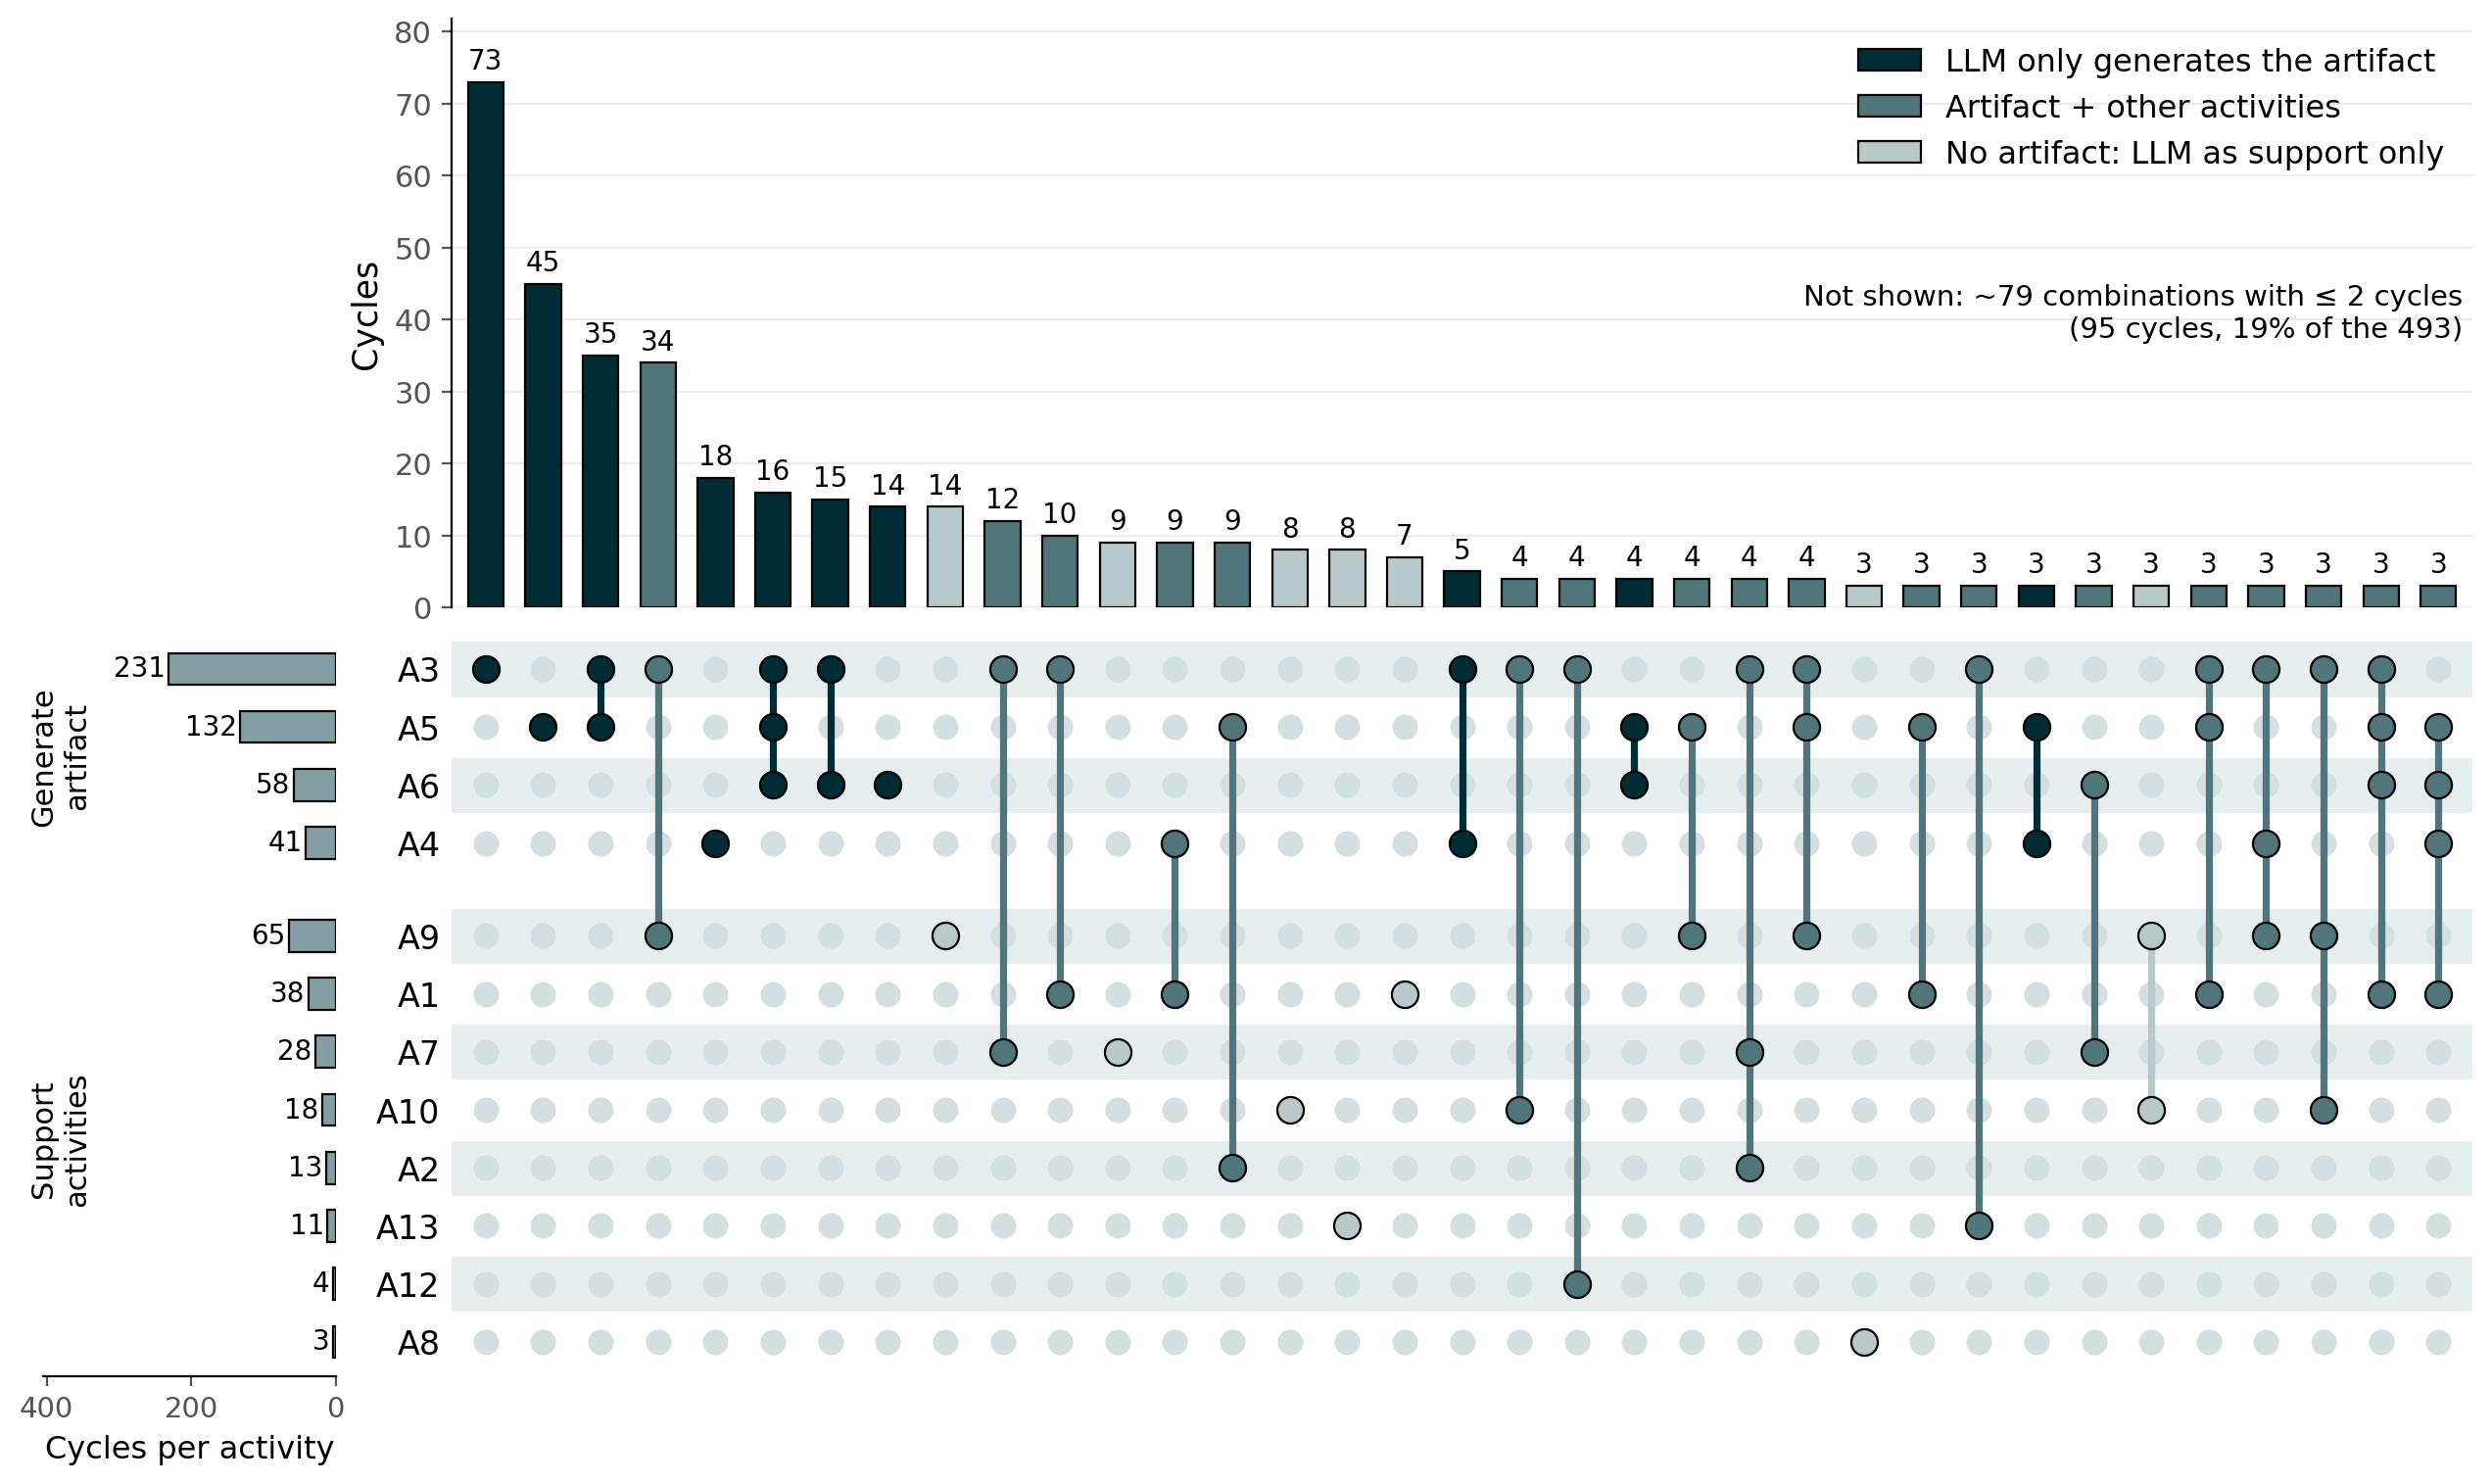

In [3]:
colunas = [(c, n) for c, n in COMBINACOES if n >= MINIMO]   # já em ordem decrescente
n_col = len(colunas)

# posição vertical de cada atividade, com um espaço entre os dois grupos
y_ativ = {}
y = 0
for a in ATIVIDADES_ARTEFATO:
    y_ativ[a] = y; y += 1
y += 0.6
for a in ATIVIDADES_APOIO:
    y_ativ[a] = y; y += 1
y_max = y - 1

fig = plt.figure(figsize=(16, 9), dpi=200)
gs = fig.add_gridspec(2, 2, width_ratios=[1.3, 9], height_ratios=[4.2, 5.3],
                      wspace=0.10, hspace=0.04)
ax_barras = fig.add_subplot(gs[0, 1])
ax_matriz = fig.add_subplot(gs[1, 1], sharex=ax_barras)
ax_totais = fig.add_subplot(gs[1, 0], sharey=ax_matriz)

x = np.arange(n_col)
cores = [CATEGORIAS[categoria(c)][1] for c, _ in colunas]

# --- barras de cima: ciclos por combinação ---
valores = [n for _, n in colunas]
ax_barras.bar(x, valores, width=0.62, color=cores, edgecolor="black", linewidth=0.8, zorder=3)
for xi, v in zip(x, valores):
    ax_barras.text(xi, v + 1, str(v), ha="center", va="bottom", fontsize=10, color="black")
ax_barras.set_ylabel("Cycles", fontsize=12.5)
ax_barras.set_ylim(0, max(valores) * 1.12)
for s in ["top", "right", "bottom"]:
    ax_barras.spines[s].set_visible(False)
ax_barras.tick_params(axis="x", bottom=False, labelbottom=False)
ax_barras.tick_params(axis="y", colors="#555555", labelsize=11)
ax_barras.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax_barras.set_axisbelow(True)
ax_barras.legend(
    handles=[Patch(facecolor=cor, edgecolor="black", linewidth=0.8, label=nome)
             for nome, cor in CATEGORIAS.values()],
    loc="upper right", frameon=False, fontsize=11.5,
)
pct_fora = CICLOS_NAO_MOSTRADOS / TOTAL_CICLOS
ax_barras.text(
    0.995, 0.50,
    f"Not shown: ~{COMBINACOES_NAO_MOSTRADAS} combinations with ≤ {MINIMO - 1} cycles\n"
    f"({CICLOS_NAO_MOSTRADOS} cycles, {pct_fora:.0%} of the {TOTAL_CICLOS})",
    transform=ax_barras.transAxes, ha="right", va="center", fontsize=10.5, color="black",
)

# --- matriz de pontos ---
for i, a in enumerate(ORDEM):
    if i % 2 == 0:   # faixas alternadas
        ax_matriz.axhspan(y_ativ[a] - 0.45, y_ativ[a] + 0.45, color=COR_FAIXA, zorder=0)
for xi, (combo, _), cor in zip(x, colunas, cores):
    ax_matriz.scatter([xi] * len(ORDEM), [y_ativ[a] for a in ORDEM], s=70,
                      color=COR_INATIVO, zorder=1)
    ys = [y_ativ[a] for a in combo]
    if len(ys) > 1:
        ax_matriz.plot([xi, xi], [min(ys), max(ys)], color=cor, linewidth=2.6, zorder=2)
    ax_matriz.scatter([xi] * len(ys), ys, s=95, color=cor, edgecolor="black",
                      linewidth=0.8, zorder=3)
ax_matriz.set_ylim(y_max + 0.6, -0.6)
ax_matriz.set_yticks([y_ativ[a] for a in ORDEM])
ax_matriz.set_yticklabels([f"A{a}" for a in ORDEM], fontsize=12)
ax_matriz.set_xlim(-0.6, n_col - 0.4)
ax_matriz.tick_params(axis="y", length=0, pad=4)
ax_matriz.tick_params(axis="x", bottom=False, labelbottom=False)
for s in ax_matriz.spines.values():
    s.set_visible(False)

# --- totais à esquerda: ciclos por atividade ---
tot = [CICLOS_POR_ATIVIDADE[a] for a in ORDEM]
ax_totais.barh([y_ativ[a] for a in ORDEM], tot, height=0.55, color=COR_TOTAIS,
               edgecolor="black", linewidth=0.8)
for a, v in zip(ORDEM, tot):
    ax_totais.text(v + 5, y_ativ[a], str(v), ha="right", va="center", fontsize=10,
                   color="black", transform=ax_totais.transData)
ax_totais.invert_xaxis()
ax_totais.set_xlim(max(tot) * 1.75, 0)
ax_totais.set_xlabel("Cycles per activity", fontsize=11.5)
ax_totais.tick_params(axis="y", left=False, labelleft=False)
ax_totais.tick_params(axis="x", colors="#555555", labelsize=10.5)
for s in ["top", "left", "right"]:
    ax_totais.spines[s].set_visible(False)

# rótulos dos dois grupos de linhas
meio_art = np.mean([y_ativ[a] for a in ATIVIDADES_ARTEFATO])
meio_apoio = np.mean([y_ativ[a] for a in ATIVIDADES_APOIO])
for yy, rot in [(meio_art, "Generate\nartifact"), (meio_apoio, "Support\nactivities")]:
    ax_totais.text(max(tot) * 1.65, yy, rot, rotation=90, ha="center", va="center",
                   fontsize=11, color="black")

plt.savefig("upset_cycles.pdf", bbox_inches="tight")
plt.savefig("upset_ciclos.png", bbox_inches="tight", dpi=200)
plt.show()